# 04 · Historia: cada rector reescribe la universidad

**Pregunta:** ¿cambia la voz oficial de la Universidad de Sonora cuando cambia quien la dirige?

El portal de noticias no es periodismo independiente: es la forma en que la universidad se cuenta a sí misma. Entre 2013 y 2026 tuvo cuatro rectorados. Si la voz institucional depende de quién está al frente, deberíamos ver que cambian tres cosas con cada transición:

1. **De qué se habla**: el vocabulario y los temas.
2. **Quién protagoniza**: cuánto aparece el propio rector o rectora.
3. **Cómo se habla**: el estilo, y en particular el lenguaje inclusivo.

| Capítulo | Pregunta | Técnica |
|---|---|---|
| 1 | ¿Cuándo cambió cada rectorado? | Detección en el texto |
| 2 | ¿Cada rectorado tiene su vocabulario? | Log-odds con prior de Dirichlet |
| 3 | ¿Y sus temas? | Modelado de temas (NMF) |
| 4 | ¿El rector es más protagonista? | Menciones en cuerpo y título |
| 5 | ¿Cambia la forma de escribir? | Lenguaje inclusivo y verbos para citar |
| 6 | ¿Las transiciones son cortes reales? | Jensen-Shannon con muestras igualadas |
| 7 | ¿Qué tanto podemos afirmar? | Controles y limitaciones |

**Entrada:** `data/processed/noticias_base.parquet` (notebook 03). Excluimos las plantillas.
**Salida:** figuras `reports/figures/hist_*.png` para la narrativa.

## 0. Configuración

In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import jensenshannon
from scipy.stats import mannwhitneyu
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ENTRADA = RAIZ / "data" / "processed" / "noticias_base.parquet"
FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 140)

def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"hist_{nombre}.png", dpi=150, bbox_inches="tight")

In [2]:
columnas = ["id", "fecha", "titulo", "texto_limpio", "lemas_frases", "ent_texto", "ent_tipo", "firma", "es_plantilla"]
df = pd.read_parquet(ENTRADA, columns=columnas)
df = df.loc[~df["es_plantilla"]].drop(columns="es_plantilla").reset_index(drop=True)
df["texto_min"] = df["texto_limpio"].str.lower()
df["trimestre"] = df["fecha"].dt.to_period("Q")
print(f"{len(df):,} notas sin plantillas, de {df['fecha'].min():%Y-%m-%d} a {df['fecha'].max():%Y-%m-%d}")

23,643 notas sin plantillas, de 2013-01-01 a 2026-10-28


## 1. Los cuatro rectorados

No necesitamos fechas externas: el propio corpus nos dice cuándo cambió el rector. Para cada persona buscamos la primera nota que la llama "rector" o "rectora". Las fechas coinciden con el cambio de rectorado de junio, cada cuatro años.

In [3]:
RECTORES = {
    "Grijalva": "heriberto grijalva",
    "Velázquez": "velázquez contreras",
    "Plancarte": "rita plancarte",
    "Camarena": "dena maría camarena|dena camarena",
}
COLORES = dict(zip(RECTORES, ["#8d99ae", "#457b9d", "#e76f51", "#2a9d8f"]))

inicio = {}
for nombre, patron in RECTORES.items():
    menciones = df.loc[df["texto_min"].str.contains(rf"\brectora? (?:\w+ ){{0,2}}(?:{patron})"), "fecha"]
    inicio[nombre] = menciones.min()
inicio["Grijalva"] = df["fecha"].min()  # su rectorado empezó antes del corpus
TRANSICIONES = pd.Series(inicio).sort_values()

df["rectorado"] = pd.cut(df["fecha"], bins=[*TRANSICIONES, pd.Timestamp.max], labels=TRANSICIONES.index, right=False)
resumen = df.groupby("rectorado", observed=True)["fecha"].agg(["min", "max", "size"])
resumen.columns = ["desde", "hasta", "notas"]
resumen

,desde,hasta,notas
rectorado,,,
Grijalva,2013-01-01,2017-06-14,9590
Velázquez,2017-06-15,2021-06-22,6365
Plancarte,2021-06-23,2025-06-15,6145
Camarena,2025-06-16,2026-10-28,1543


In [4]:
def marcar_transiciones(ax, etiquetas=True):
    # Líneas verticales en cada cambio de rectorado y banda de la pandemia
    for nombre, fecha in TRANSICIONES.iloc[1:].items():
        ax.axvline(fecha, color=COLORES[nombre], ls="--", lw=1.2)
        if etiquetas:
            ax.text(fecha, 1.01, nombre, transform=ax.get_xaxis_transform(), color=COLORES[nombre], fontsize=9)
    ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2021-08-31"), color="grey", alpha=0.12, lw=0)

Todas las gráficas en el tiempo usan las mismas marcas: una línea punteada en cada transición y una banda gris en la pandemia (marzo 2020 a agosto 2021). La pandemia cae dentro del rectorado de Velázquez y la transición a Plancarte; hay que tenerla presente para no confundir sus efectos.

## 2. El vocabulario de cada rectorado

**Pregunta:** ¿qué palabras usa un rectorado mucho más que los demás?

Usamos el **log-odds con prior de Dirichlet informativo** (Monroe, Colaresi y Quinn, 2008), el método estándar para comparar vocabularios entre grupos. A diferencia de contar frecuencias, corrige por el tamaño de cada grupo y no exagera palabras raras. El resultado es un *z-score*: mayor a 2 significa que la diferencia no es ruido.

Dos decisiones:

- **Contamos notas, no apariciones.** Una palabra repetida 20 veces en una nota cuenta una vez; así una sola nota larga no domina.
- **Quitamos los nombres de personas.** Si no, cada rectorado se distingue sobre todo por los nombres de sus funcionarios, lo cual es obvio. Consideramos nombre a una palabra que en al menos 30% de sus apariciones forma parte de una entidad `PER` detectada por spaCy.

In [5]:
en_personas = Counter(w for ents, tipos in zip(df["ent_texto"], df["ent_tipo"])
                      for e, t in zip(ents, tipos) if t == "PER" for w in e.lower().split())
en_corpus = Counter(w for doc in df["lemas_frases"] for tok in doc for w in tok.split("_"))
NOMBRES = {w for w, c in en_personas.items() if en_corpus.get(w, 0) and c / en_corpus[w] >= 0.3}

df["tokens"] = [[t for t in doc if not any(p in NOMBRES for p in t.split("_"))] for doc in df["lemas_frases"]]
antes, despues = df["lemas_frases"].map(len).sum(), df["tokens"].map(len).sum()
print(f"{len(NOMBRES):,} palabras de nombres propios; tokens {antes:,} → {despues:,} ({1 - despues / antes:.0%} menos)")

16,686 palabras de nombres propios; tokens 4,143,332 → 3,713,717 (10% menos)


In [6]:
def log_odds(docs_grupo, docs_resto, min_notas=30, alfa=0.01):
    # Log-odds con prior de Dirichlet informativo (Monroe et al., 2008), sobre frecuencia de notas
    y_i = Counter(w for d in docs_grupo for w in set(d))
    y_j = Counter(w for d in docs_resto for w in set(d))
    total = y_i + y_j
    a = {w: alfa * c for w, c in total.items()}
    a0 = sum(a.values())
    n_i, n_j = sum(y_i.values()), sum(y_j.values())
    filas = []
    for w, c in total.items():
        if c < min_notas:
            continue
        d = (np.log((y_i[w] + a[w]) / (n_i + a0 - y_i[w] - a[w]))
             - np.log((y_j[w] + a[w]) / (n_j + a0 - y_j[w] - a[w])))
        var = 1 / (y_i[w] + a[w]) + 1 / (y_j[w] + a[w])
        filas.append((w, y_i[w], d / np.sqrt(var)))
    return pd.DataFrame(filas, columns=["termino", "notas", "z"]).sort_values("z", ascending=False, ignore_index=True)

distintivos = {r: log_odds(df.loc[df["rectorado"] == r, "tokens"], df.loc[df["rectorado"] != r, "tokens"])
               for r in TRANSICIONES.index}
pd.DataFrame({r: t["termino"].head(20).values for r, t in distintivos.items()})

,Grijalva,Velázquez,Plancarte,Camarena
0,alumno,norte_urn,dirección_apoyo,fortalecer
1,citar,unidad_regional,pandemia,facultad_interdisciplinaria
2,urs,medioambiente,rectora,campus_hermosillo
3,horas,recalcar,facultad_interdisciplinaria,estudiantado
4,alma_mater,internacionalización,presencial,acompañamiento
5,director_división,contingencia_sanitario,virtual,representar
6,obra,rector,comenzar,inteligencia_artificial
7,radio,educativa,enfatizar,encuentro
8,dirección_vinculación,virtual,aseverar,espacio
9,unidad,urn,covid,acercar


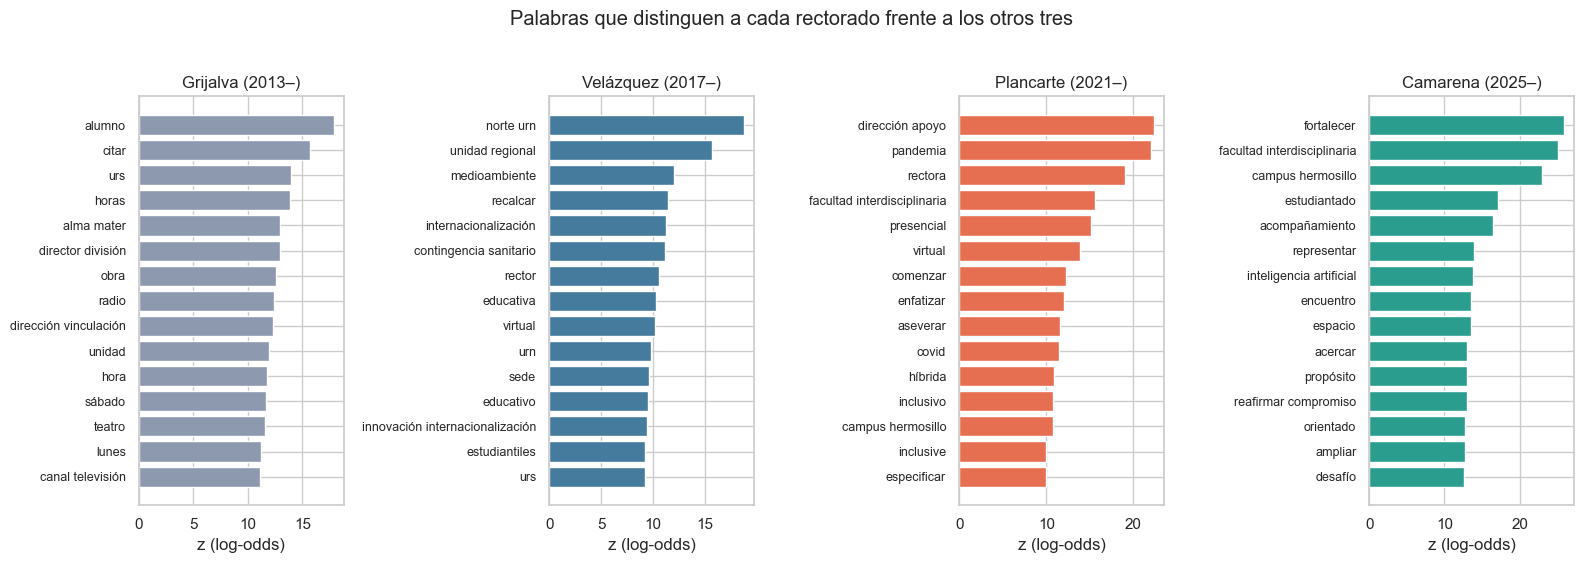

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5.5))
for ax, (r, tabla) in zip(axes, distintivos.items()):
    top = tabla.head(15).iloc[::-1]
    ax.barh(top["termino"].str.replace("_", " "), top["z"], color=COLORES[r])
    ax.set(title=f"{r} ({TRANSICIONES[r]:%Y}–)", xlabel="z (log-odds)")
    ax.tick_params(axis="y", labelsize=9)
fig.suptitle("Palabras que distinguen a cada rectorado frente a los otros tres", y=1.02)
fig.tight_layout()
guardar(fig, "vocabulario_rectorado")

### 2.1 Control: ¿es el rectorado o la pandemia?

El rectorado de Velázquez incluye el inicio de la pandemia y el de Plancarte su final. Repetimos la comparación **sin las notas de marzo 2020 a agosto 2021**. Si los términos distintivos se mantienen, no son un efecto de la pandemia.

In [8]:
sin_pandemia = df.loc[~df["fecha"].between("2020-03-15", "2021-08-31")]
control = {r: log_odds(sin_pandemia.loc[sin_pandemia["rectorado"] == r, "tokens"],
                       sin_pandemia.loc[sin_pandemia["rectorado"] != r, "tokens"]) for r in TRANSICIONES.index}

coincidencia = {}
for r in TRANSICIONES.index:
    a, b = set(distintivos[r]["termino"].head(50)), set(control[r]["termino"].head(50))
    coincidencia[r] = len(a & b) / 50
print("Términos del top 50 que se mantienen sin la pandemia:", {r: f"{v:.0%}" for r, v in coincidencia.items()})
pd.DataFrame({r: t["termino"].head(15).values for r, t in control.items()})

Términos del top 50 que se mantienen sin la pandemia: {'Grijalva': '92%', 'Velázquez': '68%', 'Plancarte': '94%', 'Camarena': '96%'}


,Grijalva,Velázquez,Plancarte,Camarena
0,alumno,norte_urn,pandemia,fortalecer
1,citar,unidad_regional,virtual,facultad_interdisciplinaria
2,urs,internacionalización,dirección_apoyo,campus_hermosillo
3,alma_mater,sede,rectora,estudiantado
4,horas,recalcar,presencial,acompañamiento
5,director_división,urs,facultad_interdisciplinaria,inteligencia_artificial
6,dirección_vinculación,educativa,enfatizar,representar
7,radio,secretaria_general,aseverar,espacio
8,obra,medioambiente,comenzar,encuentro
9,unidad_regional,sur_urs,especificar,propósito


> **Hallazgos: vocabulario**
>
> - **Cada rectorado tiene un vocabulario propio, y no es solo la coyuntura.** Sin las notas de la pandemia, se mantiene entre el 92% y el 96% del top 50 de Grijalva, Plancarte y Camarena. Velázquez baja a 68% porque parte de su perfil era la pandemia ("contingencia sanitaria", "virtual").
> - **Grijalva (2013–2017): una universidad de agenda y medios.** Radio, canal de televisión, teatro, obra. También aparecen "citar", "horas", "sábado", "lunes": notas con formato de convocatoria ("se cita a las 10 horas del sábado"). Y dice "alumno", no "estudiantado".
> - **Velázquez (2017–2021): internacionalización y medio ambiente.** "Internacionalización", "innovación e internacionalización", "medioambiente", "campo disciplinar".
> - **Plancarte (2021–2025): pandemia, regreso e inclusión.** "Pandemia", "híbrida", "presencial", "inclusivo", "inclusión y equidad" y "facultad interdisciplinaria", la reestructura de 2023.
> - **Camarena (2025–): retórica de propósito.** Sus palabras distintivas casi no son temas sino verbos y sustantivos de aspiración institucional: "fortalecer", "acompañamiento", "propósito", "desafío", "reafirmar compromiso", "consolidar", "iniciativa". Junto a ellas, "estudiantado" e "inteligencia artificial".
> - **Cuidado con los nombres de lugares.** "URS", "URN" y "unidad regional" distinguen a los primeros rectorados porque así se llamaban los campus antes de 2023. Es un cambio de nomenclatura, no de cobertura.

## 3. Los temas de cada rectorado

**Pregunta:** más allá de palabras sueltas, ¿cambia la mezcla de temas?

Usamos **NMF** (factorización de matrices no negativas) sobre TF-IDF. Frente a LDA, NMF da temas más nítidos en textos cortos y homogéneos como estas notas, y es determinista con una semilla fija. Elegimos 20 temas: suficientes para separar áreas (deporte, salud, cultura) sin fragmentarlas.

Cada nota recibe una proporción de cada tema. El peso de un tema en un rectorado es el promedio de esas proporciones en sus notas.

In [9]:
vectorizador = TfidfVectorizer(analyzer=lambda d: d, min_df=20, max_df=0.4, sublinear_tf=True)
X = vectorizador.fit_transform(df["tokens"])
nmf = NMF(n_components=20, init="nndsvda", random_state=0, max_iter=1000)
W = nmf.fit_transform(X)
W = W / np.clip(W.sum(axis=1, keepdims=True), 1e-12, None)  # proporciones por nota
vocab = vectorizador.get_feature_names_out()
palabras_tema = [" ".join(vocab[h.argsort()[::-1][:8]]) for h in nmf.components_]
print(f"Matriz TF-IDF: {X.shape[0]:,} notas × {X.shape[1]:,} términos")

Matriz TF-IDF: 23,643 notas × 10,079 términos


Las etiquetas las pusimos leyendo las palabras de cada tema; la tabla muestra ambas para que puedas verificarlas.

In [10]:
ETIQUETAS = [
    "Emprendimiento e innovación", "Música", "Economía y política nacional", "Salud",
    "Investigación y posgrado", "Congresos y foros", "Concursos y olimpiadas", "Admisión e inscripciones",
    "Gestión y vinculación", "Testimonios y vida personal", "Deporte", "Campus Navojoa (sur)",
    "Cursos y capacitación", "Ceremonias y graduaciones", "Libros, teatro y arte", "Sorteos",
    "Campus Caborca y Nogales (norte)", "Género y derechos humanos", "Evaluación y acreditación",
    "Alimentos, agua y ambiente",
]
temas = pd.DataFrame({"tema": ETIQUETAS, "palabras": palabras_tema})
temas

,tema,palabras
0,Emprendimiento e innovación,empresa negocio innovación tecnología emprendedor proyecto empresarial desarrollo
1,Música,música concierto musical piano guitarra canto interpretar artístico
2,Economía y política nacional,economía méxico económico país mexicano unidos política gobierno
3,Salud,salud enfermedad medicina médico enfermería atención paciente prevención
4,Investigación y posgrado,investigación científico posgrado investigador ciencia proyecto física área
5,Congresos y foros,evento congreso conferencia encuentro ponencia tema edición foro
6,Concursos y olimpiadas,concurso olimpiada matemáticas nacional ganador lugar obtener matemática
7,Admisión e inscripciones,aspirante examen inscripción ingreso convocatoria registro junio semestre
8,Gestión y vinculación,comunidad acción social vinculación institucional general gobierno proyecto
9,Testimonios y vida personal,persona aprender querer vida cosa experiencia joven trabajar


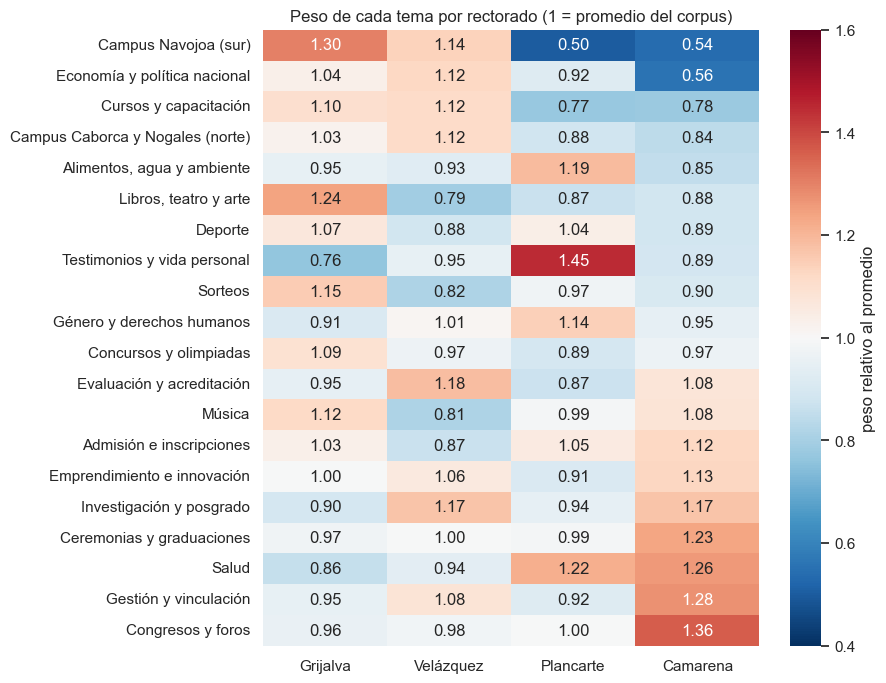

In [11]:
prop = pd.DataFrame(W, columns=ETIQUETAS)
peso = prop.groupby(df["rectorado"].astype(str).values).mean().loc[list(TRANSICIONES.index)]
relativo = peso / prop.mean()  # 1 = igual que el promedio del corpus

fig, ax = plt.subplots(figsize=(8, 8))
orden = relativo.T.sort_values("Camarena").index
sns.heatmap(relativo.T.loc[orden], cmap="RdBu_r", center=1, vmin=0.4, vmax=1.6, annot=True, fmt=".2f",
            cbar_kws={"label": "peso relativo al promedio"}, ax=ax)
ax.set(title="Peso de cada tema por rectorado (1 = promedio del corpus)", xlabel="", ylabel="")
guardar(fig, "temas_rectorado")

Rango de peso relativo entre rectorados:
 Campus Navojoa (sur)            0.80
Testimonios y vida personal     0.68
Economía y política nacional    0.57
Libros, teatro y arte           0.45
Congresos y foros               0.41
Salud                           0.40
Gestión y vinculación           0.35
Cursos y capacitación           0.34


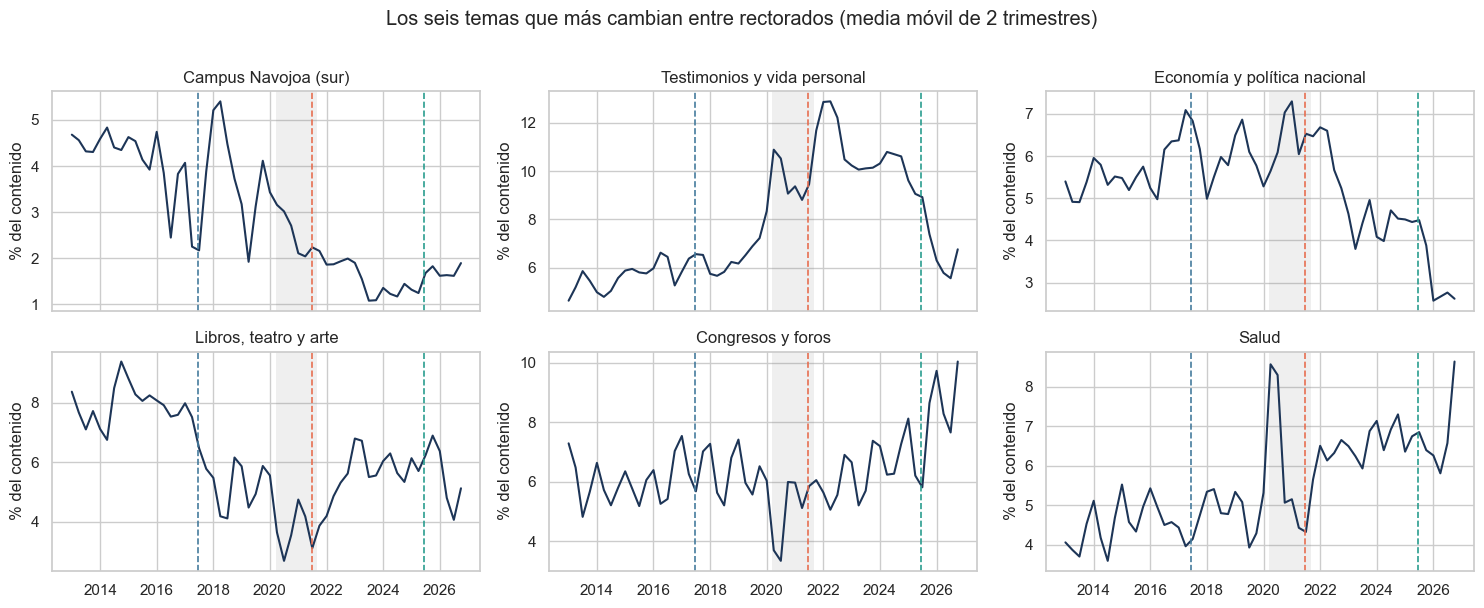

In [12]:
# Evolución trimestral de los temas que más cambian entre rectorados
cambio = (relativo.max() - relativo.min()).sort_values(ascending=False)
seleccion = cambio.index[:6]
serie = prop[seleccion].groupby(df["trimestre"].values).mean().rolling(2, min_periods=1).mean()
serie.index = serie.index.to_timestamp()

fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
for ax, tema in zip(axes.flat, seleccion):
    ax.plot(serie.index, serie[tema] * 100, color="#1d3557")
    marcar_transiciones(ax, etiquetas=False)
    ax.set(title=tema, ylabel="% del contenido")
fig.suptitle("Los seis temas que más cambian entre rectorados (media móvil de 2 trimestres)", y=1.01)
fig.tight_layout()
guardar(fig, "temas_tiempo")
print("Rango de peso relativo entre rectorados:\n", cambio.head(8).round(2).to_string())

> **Hallazgos: temas**
>
> - **La mezcla de temas se mueve, pero menos que el vocabulario.** La mayoría de los temas queda entre 0.8 y 1.2 veces el promedio en todos los rectorados: la universidad sigue hablando de investigación, deporte, salud y cultura.
> - **Grijalva** sobresale en libros, teatro y arte (1.24) y en sorteos (1.15).
> - **Plancarte** sobresale en **testimonios y vida personal** (1.45): entrevistas y relatos en primera persona, muy ligados a la pandemia. También en salud (1.22) y en alimentos, agua y ambiente (1.19).
> - **Camarena** gira hacia **la institución hablando de sí misma**: congresos y foros (1.36), gestión y vinculación (1.28) y ceremonias (1.23). En cambio, economía y política nacional cae a la mitad (0.56).
> - El tema "Campus Navojoa (sur)" cae a la mitad desde 2021, pero es el mismo artefacto de nomenclatura: el tema se formó con las palabras "URS" y "unidad regional", que dejaron de usarse.

## 4. El rector como protagonista

**Pregunta:** ¿la voz institucional se personaliza? Medimos dos cosas por trimestre:

- **Cuerpo:** % de notas que mencionan al rector o la rectora (con o sin nombre).
- **Título:** % de titulares que lo hacen. Que el rector esté en el titular indica que la nota es *sobre* él o ella, no solo que lo cita.

In [13]:
RE_RECTOR = r"\brector(?:a)?\b"
df["rector_cuerpo"] = df["texto_min"].str.contains(RE_RECTOR)
df["rector_titulo"] = df["titulo"].str.lower().str.contains(RE_RECTOR)

por_rectorado = df.groupby("rectorado", observed=True)[["rector_cuerpo", "rector_titulo"]].mean().mul(100).round(1)
por_rectorado.columns = ["% notas que lo mencionan", "% titulares"]
por_rectorado

,% notas que lo mencionan,% titulares
rectorado,,
Grijalva,10.8,2.0
Velázquez,14.4,1.9
Plancarte,13.9,1.5
Camarena,18.5,1.7


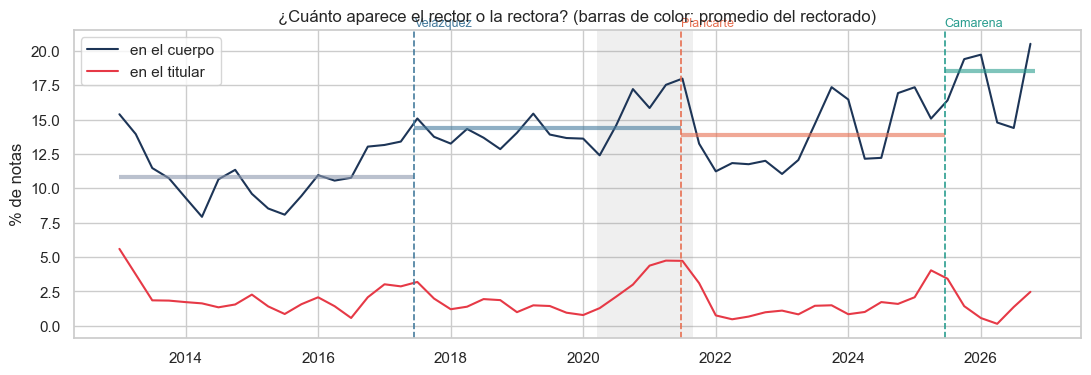

In [14]:
tri = df.groupby("trimestre")[["rector_cuerpo", "rector_titulo"]].mean().mul(100)
tri.index = tri.index.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(tri.index, tri["rector_cuerpo"].rolling(2, min_periods=1).mean(), label="en el cuerpo", color="#1d3557")
ax.plot(tri.index, tri["rector_titulo"].rolling(2, min_periods=1).mean(), label="en el titular", color="#e63946")
for r, fila in por_rectorado.iterrows():
    desde = TRANSICIONES[r]
    hasta = TRANSICIONES.shift(-1).get(r, pd.NaT)
    hasta = df["fecha"].max() if pd.isna(hasta) else hasta
    ax.hlines(fila.iloc[0], desde, hasta, color=COLORES[r], lw=3, alpha=0.6)
marcar_transiciones(ax)
ax.set(title="¿Cuánto aparece el rector o la rectora? (barras de color: promedio del rectorado)", ylabel="% de notas")
ax.legend(loc="upper left")
guardar(fig, "protagonismo")

> **Hallazgos: protagonismo**
>
> - **El rector aparece en más notas con el tiempo:** 10.8% con Grijalva, ~14% con Velázquez y Plancarte, y **18.5% con Camarena**, el máximo de la serie.
> - **Pero no ocupa más titulares** (1.5–2% en todos los rectorados). Aparece más como voz dentro de las notas, no como su tema.
> - Los picos en titulares coinciden con los **procesos de sucesión** (2017, 2021 y 2025): informes finales, designación y toma de protesta. El momento en que el rector es noticia es cuando se va o cuando llega.
> - La señal es ruidosa trimestre a trimestre. El aumento es real pero moderado; no es el hallazgo central.

## 5. Cómo se escribe: el lenguaje inclusivo

**Pregunta:** ¿cambió la forma de nombrar a la comunidad universitaria?

El español tiene tres formas de referirse a un grupo mixto, y cada una es una elección de estilo:

| Indicador | Ejemplos | Qué indica |
|---|---|---|
| **Masculino genérico** | "los alumnos", "los académicos" | La norma tradicional |
| **Desdoblamiento** | "las y los estudiantes", "niñas y niños", "académicas y académicos" | Lenguaje inclusivo explícito |
| **Colectivo neutro** | "el estudiantado", "el alumnado", "el profesorado" | Lenguaje inclusivo sin marcar género |

Medimos el % de notas que usan cada forma al menos una vez. Es una medida de **estilo**, no de tema: una nota sobre deporte puede usarla igual que una sobre género.

In [15]:
INDICADORES = {
    "Masculino genérico": r"\blos (?:alumnos|estudiantes|académicos|maestros|investigadores|profesores|egresados|universitarios)\b",
    "Desdoblamiento": r"\b(?:las y los|los y las|niñas y niños|niños y niñas|todas y todos|todos y todas|alumnas y alumnos|"
                      r"académicas y académicos|investigadoras e investigadores|maestras y maestros|profesoras y profesores|"
                      r"estudiantes mujeres y hombres|egresadas y egresados)\b",
    "Colectivo neutro": r"\b(?:estudiantado|alumnado|profesorado|personal académico|comunidad estudiantil|personal docente)\b",
}
for nombre, patron in INDICADORES.items():
    df[nombre] = df["texto_min"].str.contains(patron)
df["Inclusivo (cualquiera)"] = df["Desdoblamiento"] | df["Colectivo neutro"]
COLS_INC = [*INDICADORES, "Inclusivo (cualquiera)"]

df.groupby("rectorado", observed=True)[COLS_INC].mean().mul(100).round(1)

,Masculino genérico,Desdoblamiento,Colectivo neutro,Inclusivo (cualquiera)
rectorado,,,,
Grijalva,46.6,0.4,4.7,5.1
Velázquez,49.2,1.2,6.6,7.6
Plancarte,46.6,8.8,8.6,15.9
Camarena,39.8,24.1,21.8,37.2


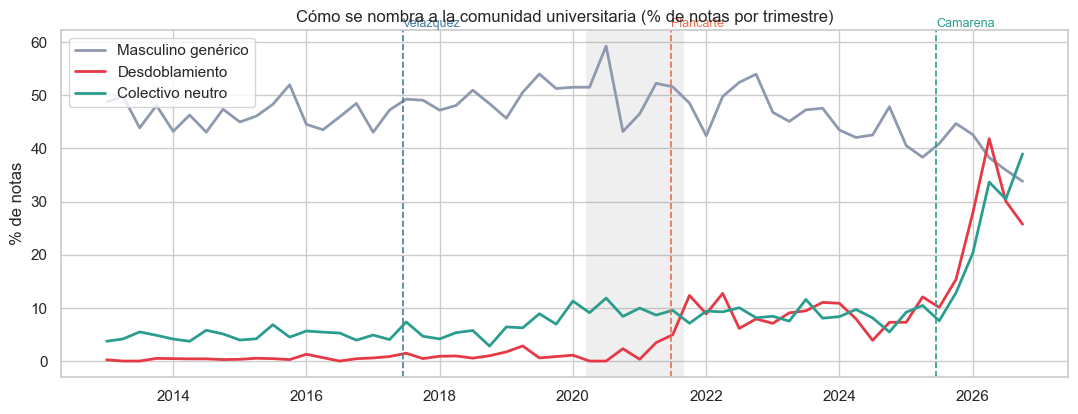

In [16]:
tri = df.groupby("trimestre")[COLS_INC].mean().mul(100)
tri.index = tri.index.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 4.5))
for col, color in zip(COLS_INC[:3], ["#8d99ae", "#e63946", "#2a9d8f"]):
    ax.plot(tri.index, tri[col], label=col, color=color, lw=2)
marcar_transiciones(ax)
ax.set(title="Cómo se nombra a la comunidad universitaria (% de notas por trimestre)", ylabel="% de notas")
ax.legend(loc="upper left")
guardar(fig, "lenguaje_inclusivo")

### 5.1 ¿Decisión editorial o gusto personal?

Si el cambio fuera de un reportero, lo veríamos en una sola firma. Si es una **línea editorial**, todas las firmas cambian a la vez. Comparamos a quienes escribieron al menos 15 notas en cada uno de cuatro periodos.

In [17]:
cortes = pd.to_datetime(["2013-01-01", "2021-06-01", "2025-06-01", "2026-01-01", "2027-01-01"])
periodos = ["2013–may 2021", "jun 2021–may 2025", "jun–dic 2025", "2026"]
df["periodo"] = pd.cut(df["fecha"], cortes, labels=periodos, right=False)

firmas = df.dropna(subset=["firma"]).groupby(["firma", "periodo"], observed=True)["Inclusivo (cualquiera)"].agg(["mean", "size"])
tabla = firmas["mean"].unstack().mul(100).round(0)
n = firmas["size"].unstack()
tabla = tabla.loc[(n[["jun 2021–may 2025", "2026"]] >= 15).all(axis=1)].sort_values("2026", ascending=False)
tabla

periodo,2013–may 2021,jun 2021–may 2025,jun–dic 2025,2026
firma,,,,
Olivia Paredes,12.0,23.0,23.0,63.0
Elías Quijada,11.0,24.0,29.0,57.0
Aleyda Gutiérrez Guerrero,4.0,14.0,45.0,56.0
Beatriz Espinoza,6.0,17.0,20.0,39.0
Paula Trespalacios Argain,NaN,6.0,12.0,38.0


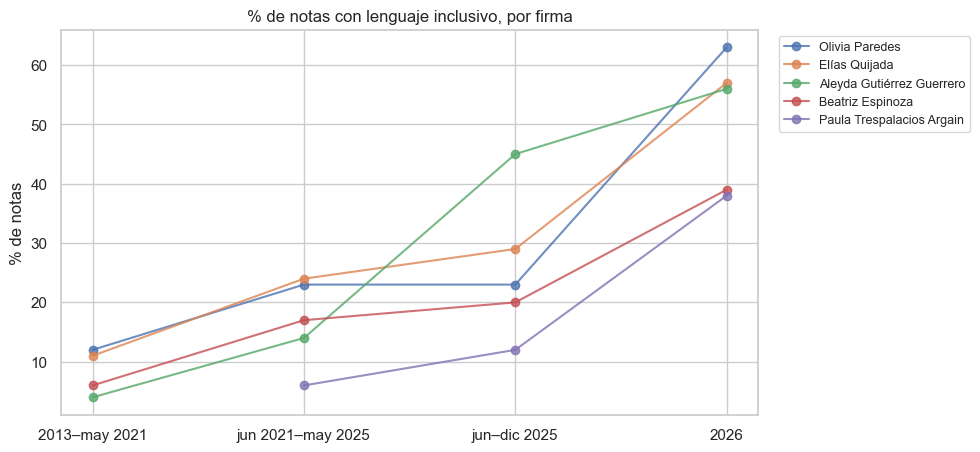

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
for firma, fila in tabla.iterrows():
    ax.plot(range(len(periodos)), fila.values, marker="o", alpha=0.8, label=firma)
ax.set_xticks(range(len(periodos)), periodos)
ax.set(title="% de notas con lenguaje inclusivo, por firma", ylabel="% de notas")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
guardar(fig, "inclusivo_por_firma")

In [19]:
# Cómo se ve en una nota: ejemplos de 2026
ejemplos = df.loc[(df["fecha"] >= "2026-01-01") & df["Desdoblamiento"]].sample(4, random_state=1)
for _, fila in ejemplos.iterrows():
    m = re.search(rf".{{0,90}}{INDICADORES['Desdoblamiento']}.{{0,60}}", fila["texto_limpio"], flags=re.I)
    print(f"{fila['fecha']:%Y-%m-%d} · {fila['titulo']}\n   «…{m.group(0) if m else ''}…»\n")

2026-05-11 · Llevan pláticas sobre alimentación y cuidado de la salud a escuelas de Caborca
   «…Durante las visitas participan las y los estudiantes María Galbán Moreno, Luz Elena Moreno Parra, It…»

2026-10-07 · Impulsan emprendimiento e innovación gastronómica con chiltepín
   «…Precisó que la jornada se desarrolló de 10:00 a 12:00 horas, lapso en el que las y los participantes ofrecieron degustaciones a la comunidad unive…»

2026-09-08 · Exhiben legado del arquitecto Daniel Marín Botello
   «…También se reconoció la colaboración de las y los estudiantes que participaron en la revisión y clasificación…»

2026-03-05 · Imponen filipinas a nuevos practicantes de Licenciatura en Psicología
   «…gar Isaac Ortega Méndez, jefe del Departamento de Ciencias Sociales, felicitó y convocó a las y los jóvenes a portar su nueva filipina con la sensibilidad, pru…»



### 5.2 ¿Se anunció el cambio?

Si la universidad adoptó una guía de lenguaje incluyente, esperaríamos alguna nota que lo anuncie.

In [20]:
RE_GUIA = r"lenguaje (?:incluyente|inclusivo|no sexista)|guía de (?:comunicación|lenguaje)|manual de (?:estilo|lenguaje)"
mencion = df.loc[df["texto_min"].str.contains(RE_GUIA)]
print("Notas que hablan de lenguaje incluyente, por año:", mencion.groupby(mencion["fecha"].dt.year).size().to_dict())
mencion.loc[mencion["fecha"] >= "2021-01-01", ["fecha", "titulo"]]

Notas que hablan de lenguaje incluyente, por año: {2015: 1, 2016: 2, 2019: 3, 2020: 5, 2021: 6, 2022: 2, 2023: 7, 2024: 2, 2025: 2, 2026: 3}


,fecha,titulo
15480,2021-02-04,Promoverán Unison y Ayuntamiento de Hermosillo la inclusión de la comunidad sorda
15769,2021-04-29,Capacitan a alumnos del campus Caborca en el uso de lenguaje no sexista
16215,2021-09-23,Juzgar con perspectiva de género garantiza los derechos humanos: Esequiel Rico Aguirre
16274,2021-10-04,Resalta académico importancia de transversalizar la perspectiva de género en las IES
16412,2021-10-26,Ofrece la universidad cursos para una mejor educación en línea
16588,2021-11-25,"En la Universidad de Sonora, ninguna mujer está sola: María Rita Plancarte"
17622,2022-08-04,Reconoce a nivel nacional labor de académicas en equidad de género
18248,2022-12-02,Reflexionan sobre la igualdad para las mujeres
18592,2023-03-01,Inicia Foro Internacional de Lingüística y Literatura
18922,2023-05-03,Promueve nuevas narrativas el Encuentro Nacional de Gacetas y Revistas Universitarias


### 5.3 Otro rasgo de estilo: los verbos para citar

Cada vez que una nota cita a alguien, el redactor elige un verbo. En periodismo, "dijo" es el verbo **neutro** por excelencia. Otros verbos **valoran** lo dicho ("destacó", "subrayó", "enfatizó": implican que es importante) o lo presentan como **explicación** ("explicó", "detalló", "compartió"). Que una redacción pase de "dijo" a "destacó" es un cambio de tono: de informar a promover.

Contamos los verbos de cita en pasado (tercera persona) y calculamos qué proporción representa cada uno dentro de todas las citas del rectorado.

In [21]:
VERBOS_CITA = {
    "neutro": ["dijo", "señaló", "comentó", "indicó", "mencionó", "agregó", "añadió", "apuntó", "refirió", "afirmó", "sostuvo", "expresó"],
    "valorativo": ["destacó", "subrayó", "resaltó", "enfatizó", "recalcó", "puntualizó", "reconoció", "aseveró", "advirtió"],
    "explicativo": ["explicó", "detalló", "precisó", "compartió", "especificó", "abundó"],
}
tipo_verbo = {v: t for t, vs in VERBOS_CITA.items() for v in vs}
RE_CITA = re.compile(r"\b(" + "|".join(tipo_verbo) + r")\b")

citas = pd.DataFrame([(r, f, v) for r, f, texto in zip(df["rectorado"], df["fecha"], df["texto_min"])
                      for v in RE_CITA.findall(texto)], columns=["rectorado", "fecha", "verbo"])
citas["tipo"] = citas["verbo"].map(tipo_verbo)
print(f"{len(citas):,} verbos de cita")

por_verbo = pd.crosstab(citas["verbo"], citas["rectorado"], normalize="columns").mul(100).round(1)[list(TRANSICIONES.index)]
por_verbo.sort_values("Camarena", ascending=False).head(15)

108,224 verbos de cita


rectorado,Grijalva,Velázquez,Plancarte,Camarena
verbo,,,,
destacó,6.6,8.6,6.3,12.7
señaló,9.4,8.4,7.7,9.6
explicó,3.8,5.0,6.7,9.5
expresó,6.7,6.5,7.8,8.0
dijo,18.4,15.2,15.2,6.5
indicó,8.0,9.0,7.3,5.3
añadió,8.2,6.3,5.7,5.0
compartió,0.7,1.3,2.3,4.8
detalló,0.6,1.5,2.7,4.7


tipo,explicativo,neutro,valorativo
rectorado,,,
Grijalva,8.1,71.5,20.4
Velázquez,11.6,67.7,20.7
Plancarte,17.3,63.2,19.5
Camarena,23.9,45.9,30.2


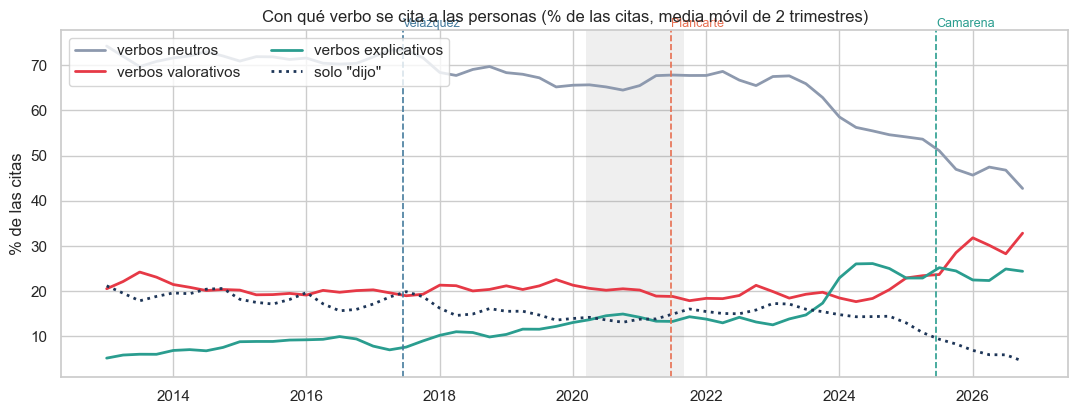

In [22]:
tipo_tri = pd.crosstab(citas["fecha"].dt.to_period("Q"), citas["tipo"], normalize="index").mul(100)
tipo_tri.index = tipo_tri.index.to_timestamp()
dijo_tri = citas.assign(dijo=citas["verbo"] == "dijo").groupby(citas["fecha"].dt.to_period("Q"))["dijo"].mean().mul(100)
dijo_tri.index = dijo_tri.index.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 4.5))
for col, color in zip(["neutro", "valorativo", "explicativo"], ["#8d99ae", "#e63946", "#2a9d8f"]):
    ax.plot(tipo_tri.index, tipo_tri[col].rolling(2, min_periods=1).mean(), label=f"verbos {col}s", color=color, lw=2)
ax.plot(dijo_tri.index, dijo_tri.rolling(2, min_periods=1).mean(), label='solo "dijo"', color="#1d3557", ls=":", lw=2)
marcar_transiciones(ax)
ax.set(title="Con qué verbo se cita a las personas (% de las citas, media móvil de 2 trimestres)", ylabel="% de las citas")
ax.legend(loc="upper left", ncols=2)
guardar(fig, "verbos_cita")
pd.crosstab(citas["rectorado"], citas["tipo"], normalize="index").mul(100).round(1).loc[list(TRANSICIONES.index)]

> **Hallazgos: lenguaje**
>
> - **Este es el cambio más fuerte de todo el corpus.** El desdoblamiento ("las y los estudiantes") pasa del **0.4% de las notas con Grijalva al 24% con Camarena**, y los colectivos neutros ("estudiantado") del 4.7% al 21.8%. Usar cualquiera de las dos formas pasa del 5% al 37% de las notas.
> - **Llega en dos escalones.** Uno pequeño con la primera rectora (2021: el desdoblamiento sube de ~1% a ~10%) y uno grande en **2026** (+15 y +19 puntos en el primer y segundo trimestre). El segundo llega unos seis meses después de que asume Camarena.
> - **Es una línea editorial, no un gusto personal.** Las cinco firmas principales cambian al mismo tiempo: Olivia Paredes pasa de 23% a 63% y Aleyda Gutiérrez de 14% a 56%. Ninguna lo hacía antes por su cuenta.
> - **Nadie lo anunció.** El corpus casi no habla de lenguaje incluyente (de 1 a 7 notas por año, sobre talleres y foros de género). El cambio se *practica*, no se *comunica*. Para confirmar la causa hay que buscar fuera del corpus (por ejemplo, una guía de estilo de la Dirección de Comunicación).
> - **El tono también cambia: de informar a promover.** "Dijo" era el 18.4% de las citas con Grijalva y es el **6.5% con Camarena**. Lo reemplazan verbos que valoran ("destacó" pasa de 6.6% a 12.7%) o que presentan lo dicho como explicación ("explicó", "detalló", "compartió"). Los verbos neutros caen del 71.5% al 45.9%. Este cambio empieza hacia 2024, antes de Camarena, y se acelera con ella.

## 6. ¿Las transiciones son cortes reales?

Hasta aquí comparamos rectorados como bloques. Pero el lenguaje cambia siempre un poco: ¿los cambios de rector producen saltos **más grandes** que el cambio normal?

Medimos la **divergencia de Jensen-Shannon** (JS) entre la distribución de palabras de dos trimestres. Va de 0 (idénticos) a 1 (sin palabras en común). Usamos las 5,000 palabras más frecuentes.

**Trampa a evitar:** la JS calculada con pocos textos sale inflada, porque el azar del muestreo también la sube. Los trimestres de la pandemia y los de 2025–2026 tienen menos notas, así que parecerían "cortes" aunque no lo sean. Por eso:

1. Comparamos siempre **muestras del mismo tamaño** (90 notas por trimestre, 20 repeticiones).
2. Medimos el **ruido de base**: la JS entre dos mitades al azar del *mismo* trimestre. Un salto real tiene que superarlo con claridad.

In [23]:
vocab_js = [w for w, _ in Counter(w for d in df["tokens"] for w in d).most_common(5000)]
indice = {w: i for i, w in enumerate(vocab_js)}
K, REPETICIONES = 90, 20
rng = np.random.default_rng(0)

def distribucion(docs):
    v = np.zeros(len(vocab_js))
    for d in docs:
        for w in d:
            j = indice.get(w)
            if j is not None:
                v[j] += 1
    return v / v.sum()

def js_igualado(a, b):
    # JS promedio entre muestras de K notas de cada grupo
    return np.mean([jensenshannon(distribucion(rng.choice(a, K, replace=False)),
                                  distribucion(rng.choice(b, K, replace=False))) for _ in range(REPETICIONES)])

def ruido(a):
    # JS entre dos mitades disjuntas del mismo grupo
    vals = []
    for _ in range(REPETICIONES):
        idx = rng.permutation(len(a))
        vals.append(jensenshannon(distribucion([a[i] for i in idx[:K]]), distribucion([a[i] for i in idx[K:2 * K]])))
    return np.mean(vals)

def como_arreglo(docs):
    # Arreglo 1-D de listas (np.array crearía una matriz si todas midieran igual)
    arr = np.empty(len(docs), dtype=object)
    arr[:] = list(docs)
    return arr

grupos = {q: como_arreglo(g) for q, g in df.groupby("trimestre")["tokens"]}
qs = sorted(q for q in grupos if len(grupos[q]) >= 2 * K)
print("Trimestres excluidos por tener menos de", 2 * K, "notas:", [str(q) for q in grupos if q not in qs])

saltos = pd.DataFrame({"js": [js_igualado(grupos[a], grupos[b]) for a, b in zip(qs, qs[1:])],
                       "ruido": [(ruido(grupos[a]) + ruido(grupos[b])) / 2 for a, b in zip(qs, qs[1:])]},
                      index=pd.PeriodIndex(qs[1:]).to_timestamp())
saltos["exceso"] = saltos["js"] - saltos["ruido"]
print(f"Ruido de base: mediana {saltos['ruido'].median():.3f}; salto entre trimestres: mediana {saltos['js'].median():.3f}")
saltos.sort_values("exceso", ascending=False).head(8).round(3)

Trimestres excluidos por tener menos de 180 notas: ['2020Q2', '2020Q3', '2026Q4']


Ruido de base: mediana 0.353; salto entre trimestres: mediana 0.371


,js,ruido,exceso
2020-10-01,0.363,0.326,0.038
2026-07-01,0.369,0.333,0.036
2026-01-01,0.361,0.335,0.026
2014-01-01,0.404,0.378,0.026
2024-10-01,0.372,0.348,0.025
2026-04-01,0.362,0.338,0.024
2025-04-01,0.371,0.348,0.023
2019-01-01,0.380,0.356,0.023


Llegada de Velázquez: trimestre 2017-04, exceso 0.015 (percentil 35%)
Llegada de Velázquez: trimestre 2017-07, exceso 0.016 (percentil 52%)
Llegada de Plancarte: trimestre 2021-04, exceso 0.014 (percentil 21%)
Llegada de Plancarte: trimestre 2021-07, exceso 0.016 (percentil 60%)
Llegada de Camarena: trimestre 2025-04, exceso 0.023 (percentil 88%)
Llegada de Camarena: trimestre 2025-07, exceso 0.018 (percentil 73%)


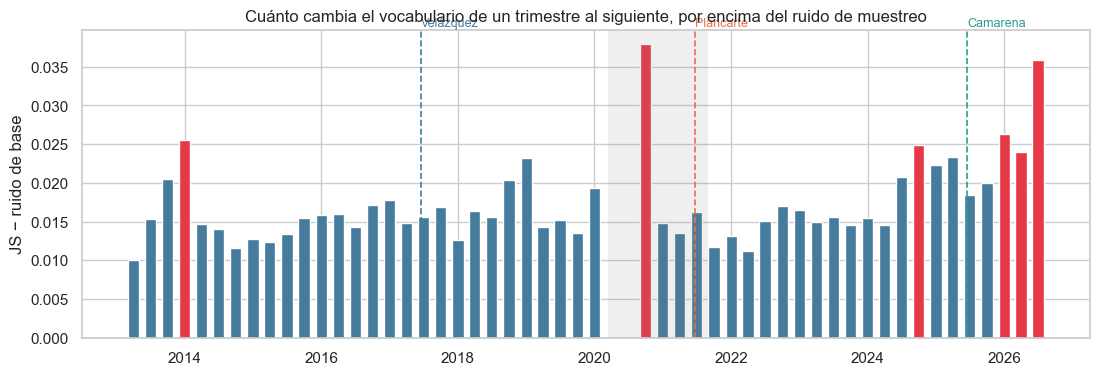

In [24]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(saltos.index, saltos["exceso"], width=60, color=np.where(saltos["exceso"] > saltos["exceso"].quantile(0.9), "#e63946", "#457b9d"))
marcar_transiciones(ax)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Cuánto cambia el vocabulario de un trimestre al siguiente, por encima del ruido de muestreo",
       ylabel="JS − ruido de base")
guardar(fig, "cortes_vocabulario")
transicion_q = [pd.Timestamp(f).to_period("Q").to_timestamp() for f in TRANSICIONES.iloc[1:]]
pct = saltos["exceso"].rank(pct=True)
for nombre, q in zip(TRANSICIONES.index[1:], transicion_q):
    siguiente = saltos.index[saltos.index > q][:1]
    for t in [q, *siguiente]:
        if t in saltos.index:
            print(f"Llegada de {nombre}: trimestre {t:%Y-%m}, exceso {saltos.loc[t, 'exceso']:.3f} (percentil {pct[t]:.0%})")

### 6.1 Prueba con pares a un año de distancia

Comparamos **pares de trimestres separados exactamente un año**: unos dentro del mismo rectorado y otros que cruzan una transición. Así la distancia en el tiempo es la misma y solo cambia si hubo transición. Excluimos los pares que tocan la pandemia.

Pares dentro del mismo rectorado: 32, mediana JS 0.375
Pares que cruzan una transición:   8, mediana JS 0.379
Mann-Whitney U (cruza > dentro): p = 0.480


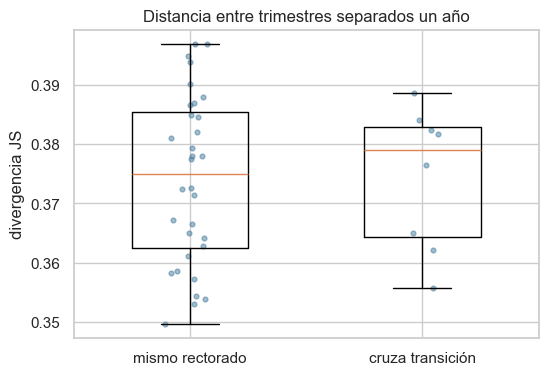

In [25]:
rect_q = df.groupby("trimestre")["rectorado"].agg(lambda s: s.mode().iloc[0]).astype(str)
pandemia = pd.period_range("2020Q1", "2021Q3", freq="Q")
pares = pd.DataFrame([{"desde": q, "js": js_igualado(grupos[q], grupos[q + 4]), "cruza": rect_q[q] != rect_q[q + 4]}
                      for q in qs if q + 4 in qs and q not in pandemia and q + 4 not in pandemia])

dentro, cruza = pares.loc[~pares["cruza"], "js"], pares.loc[pares["cruza"], "js"]
prueba = mannwhitneyu(cruza, dentro, alternative="greater")
print(f"Pares dentro del mismo rectorado: {len(dentro)}, mediana JS {dentro.median():.3f}")
print(f"Pares que cruzan una transición:   {len(cruza)}, mediana JS {cruza.median():.3f}")
print(f"Mann-Whitney U (cruza > dentro): p = {prueba.pvalue:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([dentro, cruza], labels=["mismo rectorado", "cruza transición"], widths=0.5)
ax.scatter(np.r_[np.full(len(dentro), 1), np.full(len(cruza), 2)] + rng.normal(0, 0.04, len(pares)),
           np.r_[dentro, cruza], s=12, alpha=0.5, color="#457b9d")
ax.set(title="Distancia entre trimestres separados un año", ylabel="divergencia JS")
guardar(fig, "prueba_transiciones")

### 6.2 Contraste: el estilo sí tiene cortes

Para comparar, hacemos la misma pregunta con el indicador de lenguaje inclusivo: ¿en qué trimestres da los mayores saltos respecto al trimestre anterior?

In [26]:
inc_tri = df.groupby("trimestre")["Inclusivo (cualquiera)"].mean().mul(100)
salto_inc = inc_tri.diff().dropna()
salto_inc.index = salto_inc.index.astype(str)
salto_inc.nlargest(5).round(1).rename("puntos porcentuales")

trimestre
2026Q2    18.7
2026Q1    15.4
2025Q4     7.9
2026Q4     5.4
2020Q1     4.8
Name: puntos porcentuales, dtype: float64

> **Hallazgos: cortes**
>
> - **Las transiciones no son cortes de vocabulario.** Al corregir por el tamaño de las muestras, los trimestres de llegada de Velázquez y Plancarte quedan en un salto normal (percentiles 21–60%). Los de Camarena quedan más altos (73–88%), pero no extremos. Comparando trimestres separados un año, cruzar una transición no da distancias mayores (p = 0.48).
> - **El salto más grande es la pandemia** (finales de 2020, el regreso tras el cierre), seguido de los trimestres de 2026.
> - **La primera versión de este análisis engañaba.** Sin igualar el tamaño de las muestras, 2025–2026 parecía el mayor corte de la serie, pero era un efecto de que esos trimestres tienen menos notas. Es una trampa común con la divergencia JS.
> - **En cambio, el estilo sí tiene cortes.** Los mayores saltos del indicador de lenguaje inclusivo son de 15 a 19 puntos en un solo trimestre (2026T1 y 2026T2). **De qué se habla cambia poco a poco; cómo se habla cambia por decisión.**

## 7. Conclusiones, límites y guion de la narrativa

### Respuesta a la pregunta

**Sí, la voz oficial cambia con quien dirige la universidad, pero no como esperábamos.**

- **Lo que cambia poco a poco es el tema.** Cada rectorado tiene vocabulario y temas distintivos, y resisten el control por la pandemia. Pero no hay un corte el día que llega el nuevo rector: la agenda se desliza trimestre a trimestre.
- **Lo que cambia de golpe es la forma.** El lenguaje inclusivo pasa de casi inexistente a estar en más de un tercio de las notas, en todas las firmas a la vez, sin ninguna nota que lo anuncie. Los verbos para citar pasan de "dijo" a "destacó". Son decisiones de estilo, y se notan más que cualquier cambio de agenda.
- **La universidad habla cada vez más de sí misma.** Con Camarena crecen el rector como voz (18.5% de las notas), los congresos, la gestión y las ceremonias, y su vocabulario distintivo es retórica institucional ("fortalecer", "propósito", "reafirmar compromiso").

### Límites (lo que no podemos afirmar)

1. **Asociación, no causa.** Que el cambio coincida con un rectorado no prueba que el rector lo haya ordenado. Pudo cambiar la dirección de comunicación, llegar una guía nacional o cambiar la norma social. La causa hay que confirmarla con fuentes externas.
2. **Camarena tiene poco tiempo en el corpus:** 1,543 notas en 16 meses. Sus resultados son los más frágiles.
3. **Variables mezcladas:** la pandemia cae en el cambio Velázquez–Plancarte y la reestructura de 2023 dentro de Plancarte. Controlamos la primera; la segunda deja huella en la nomenclatura (URS → campus).
4. **Las expresiones regulares no cubren todo:** el indicador de lenguaje inclusivo cuenta formas frecuentes, no todas. Sirve para comparar en el tiempo, no como medida absoluta.
5. **Es una sola voz:** el portal oficial. La historia es sobre cómo se presenta la universidad, no sobre lo que pasó en ella.

### Guion para la narrativa

| # | Momento | Mensaje | Figura |
|---|---|---|---|
| 1 | Gancho | En 2013, menos de 1 de cada 100 notas decía "las y los"; en 2026, 1 de cada 3 | `hist_lenguaje_inclusivo.png` |
| 2 | Contexto | Cuatro rectorados en 14 años, detectados desde el propio texto | tabla de la sección 1 |
| 3 | Cada época, sus palabras | De la radio y el teatro a la internacionalización, la pandemia y el "propósito" | `hist_vocabulario_rectorado.png` |
| 4 | La agenda | Los temas se mueven, y la universidad habla cada vez más de sí misma | `hist_temas_rectorado.png` |
| 5 | El tono | De "dijo" a "destacó": de informar a promover | `hist_verbos_cita.png` |
| 6 | No fue una persona | Todas las firmas cambian a la vez | `hist_inclusivo_por_firma.png` |
| 7 | El giro | El vocabulario cambia poco a poco; la forma cambia de golpe | `hist_cortes_vocabulario.png` |
| 8 | Cierre | Quién dirige no cambia tanto de qué se habla como **cómo** se habla. Pregunta abierta: ¿quién decidió el cambio de 2026? | — |